In [1]:
import numpy as np
import  pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import os
import torch, torchaudio
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import IPython.display as ipd
import random
import seaborn as sns
from sklearn.model_selection import StratifiedShuffleSplit

# Data Loading Pipeline

In [2]:
BASE = "/kaggle/input/competitions/birdclef-2025"  # <-- CHANGE THIS to what FOUND printed
# example: BASE = "/kaggle/input/birdclef-2025/birdclef-2025" if needed

train = pd.read_csv(f"{BASE}/train.csv")
taxonomy = pd.read_csv(f"{BASE}/taxonomy.csv")
print(BASE, train.shape)

/kaggle/input/competitions/birdclef-2025 (28564, 13)


In [3]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
sample_df=train.sample(frac=0.3,random_state=42)
sample_df.shape

(8569, 13)

In [5]:
labels=sorted(train['primary_label'].unique())
label2idx={l:i for i,l in enumerate(labels)}
idx2label={i:l for l,i in label2idx.items()}
class CFG:
    SR=32000
    DURATION=5
    N_MELS=128
    BATCH=32
class BirdDataset(Dataset):
    def __init__(self, df):
        self.df = df
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=CFG.SR, n_mels=CFG.N_MELS, f_min=50, f_max=14000, n_fft=1024, hop_length=512
        )
        self.db = torchaudio.transforms.AmplitudeToDB()

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        row=self.df.iloc[idx]
        path = os.path.join(BASE, "train_audio", row['filename'])
        wav,sr=torchaudio.load(path)
        wav=wav.mean(dim=0)
        if sr != CFG.SR:
            resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=CFG.SR)
            wav = resampler(wav)
        target = CFG.SR * CFG.DURATION
        if len(wav) > target:
            start = torch.randint(0, len(wav)-target, (1,)).item()
            wav = wav[start:start+target]
        else:
            wav = F.pad(wav, (0, target - len(wav)))
            
        mel = self.mel(wav)
        mel = self.db(mel)
        mel = (mel - mel.mean()) / (mel.std() + 1e-6)
        
        label = label2idx[row['primary_label']]
        return mel, label


In [6]:
splitter=StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
counts=sample_df['primary_label'].value_counts()
rare_classes=counts[counts==1].index
sample_df = sample_df[~sample_df['primary_label'].isin(rare_classes)].reset_index(drop=True)

In [7]:
sample_df.shape

(8555, 13)

In [8]:
train_idx, val_idx = next(splitter.split(sample_df, sample_df['primary_label']))

In [9]:
train_df = sample_df.iloc[train_idx].reset_index(drop=True)
val_df = sample_df.iloc[val_idx].reset_index(drop=True)

print(f"Train size: {len(train_df)} | Val size: {len(val_df)}")

Train size: 6844 | Val size: 1711


In [10]:
train_dataset=BirdDataset(train_df)
val_dataset=BirdDataset(val_df)

In [13]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

In [14]:
mels, labs = next(iter(train_loader))
print("Batch shape:", mels.shape)       
print("Labels shape:", labs.shape)

Batch shape: torch.Size([16, 128, 313])
Labels shape: torch.Size([16])


# Pure AST Model

In [31]:
from transformers import ASTForAudioClassification, ASTConfig
import torch
import torch.nn.functional as F

# 1. Load config and model (no max_length hacking)
config = ASTConfig.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593")
config.num_labels = 206
config.num_mel_bins = 128

model = ASTForAudioClassification.from_pretrained(
    "MIT/ast-finetuned-audioset-10-10-0.4593",
    config=config,
    ignore_mismatched_sizes=True
).to(device)

# 2. 🔥 THE MAGIC FIX: Interpolate position embeddings to length 362
# We know from the error that the actual sequence length is 362.
# The original pos_emb is shape [1, 1214, 768]. We resize the 1214 to 362.
old_pos = model.audio_spectrogram_transformer.embeddings.position_embeddings
# Reshape for interpolate: [1, 1214, 768] -> [1, 768, 1214]
new_pos = F.interpolate(
    old_pos.permute(0, 2, 1), 
    size=362, 
    mode='linear', 
    align_corners=False
).permute(0, 2, 1) # Back to [1, 362, 768]

# Assign it back as a Parameter so it's still trainable
model.audio_spectrogram_transformer.embeddings.position_embeddings = torch.nn.Parameter(new_pos)

print(f"✅ New position embeddings shape: {model.audio_spectrogram_transformer.embeddings.position_embeddings.shape}")

# 3. Sanity check
dummy = torch.randn(2, 128, 313).to(device)
with torch.no_grad():
    out = model(dummy).logits
print(f"✅ Output shape: {out.shape}") # Must be [2, 206]

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                           
------------------------+----------+-------------------------------------------------------------------------------------------
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([206, 768])
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([206])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


✅ New position embeddings shape: torch.Size([1, 362, 768])
✅ Output shape: torch.Size([2, 206])


In [17]:
print(model)

ASTForAudioClassification(
  (audio_spectrogram_transformer): ASTModel(
    (embeddings): ASTEmbeddings(
      (patch_embeddings): ASTPatchEmbeddings(
        (projection): Conv2d(1, 768, kernel_size=(16, 16), stride=(10, 10))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ASTLayer(
        (attention): ASTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (mlp): ASTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Li

In [19]:
# Total
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {total/1e6:.1f}M | Trainable: {trainable/1e6:.1f}M")

# Per top-level module
for name, mod in model.named_children():
    n = sum(p.numel() for p in mod.parameters())
    print(f"{name:40s} {n/1e6:8.2f}M")

Total params: 85.7M | Trainable: 85.7M
audio_spectrogram_transformer               85.53M
classifier                                   0.16M


In [21]:
# for name, p in model.named_parameters():
#     print(f"{name:70s} {tuple(p.shape)}  requires_grad={p.requires_grad}")

In [23]:
with torch.no_grad():
    out = model(torch.randn(2, 128, 313).to(device))
print(type(out))            # AudioClassifierOutput
print(out.keys())           # ['logits']  (or ['logits','hidden_states',...])
print(out.logits.shape)     # torch.Size([2, 206])

<class 'transformers.modeling_outputs.SequenceClassifierOutput'>
odict_keys(['logits'])
torch.Size([2, 206])


In [25]:
# from transformers import AutoConfig, ASTForAudioClassification

# cfg = AutoConfig.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593")
# print(cfg)                                         # all hyperparams
# model = ASTForAudioClassification(cfg)             # uninitialized, same arch
# print(model)                                       # layer tree without downloading 346MB

# Training Loop

In [35]:
model.config

ASTConfig {
  "architectures": [
    "ASTForAudioClassification"
  ],
  "attention_probs_dropout_prob": 0.0,
  "dtype": "float32",
  "frequency_stride": 10,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "id2label": {
    "0": "LABEL_0",
    "1": "LABEL_1",
    "2": "LABEL_2",
    "3": "LABEL_3",
    "4": "LABEL_4",
    "5": "LABEL_5",
    "6": "LABEL_6",
    "7": "LABEL_7",
    "8": "LABEL_8",
    "9": "LABEL_9",
    "10": "LABEL_10",
    "11": "LABEL_11",
    "12": "LABEL_12",
    "13": "LABEL_13",
    "14": "LABEL_14",
    "15": "LABEL_15",
    "16": "LABEL_16",
    "17": "LABEL_17",
    "18": "LABEL_18",
    "19": "LABEL_19",
    "20": "LABEL_20",
    "21": "LABEL_21",
    "22": "LABEL_22",
    "23": "LABEL_23",
    "24": "LABEL_24",
    "25": "LABEL_25",
    "26": "LABEL_26",
    "27": "LABEL_27",
    "28": "LABEL_28",
    "29": "LABEL_29",
    "30": "LABEL_30",
    "31": "LABEL_31",
    "32": "LABEL_32",
    "33": "LABEL_33",
    "34": "LABEL_34",
 

In [36]:
emb = model.audio_spectrogram_transformer.embeddings

print("Position embeddings:", emb.position_embeddings.shape)
print("Patch projection:", emb.patch_embeddings.projection)
print("CLS token:", emb.cls_token.shape)
print("Distillation token:", emb.distillation_token.shape)

Position embeddings: torch.Size([1, 362, 768])
Patch projection: Conv2d(1, 768, kernel_size=(16, 16), stride=(10, 10))
CLS token: torch.Size([1, 1, 768])
Distillation token: torch.Size([1, 1, 768])


In [37]:
help(model.forward)

Help on method forward in module transformers.models.audio_spectrogram_transformer.modeling_audio_spectrogram_transformer:

forward(
    input_values: torch.Tensor | None = None,
    labels: torch.Tensor | None = None,
    attention_mask: torch.Tensor | None = None,
    **kwargs: Unpack[transformers.utils.generic.TransformersKwargs]
) -> transformers.modeling_outputs.SequenceClassifierOutput method of transformers.models.audio_spectrogram_transformer.modeling_audio_spectrogram_transformer.ASTForAudioClassification instance
    The [`ASTForAudioClassification`] forward method, overrides the `__call__` special method.

    <Tip>

    Although the recipe for forward pass needs to be defined within this function, one should call the [`Module`]
    instance afterwards instead of this since the former takes care of running the pre and post processing steps while
    the latter silently ignores them.

    </Tip>

    Args:
        input_values (`torch.FloatTensor` of shape `(batch_size, max_l

In [38]:
import inspect

print(inspect.getsource(
    model.audio_spectrogram_transformer.embeddings.forward
))

    def forward(self, input_values: torch.Tensor) -> torch.Tensor:
        batch_size = input_values.shape[0]
        embeddings = self.patch_embeddings(input_values)

        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        distillation_tokens = self.distillation_token.expand(batch_size, -1, -1)
        embeddings = torch.cat((cls_tokens, distillation_tokens, embeddings), dim=1)
        embeddings = embeddings + self.position_embeddings
        embeddings = self.dropout(embeddings)

        return embeddings



In [33]:
import time
import torch.optim as optim
import matplotlib.pyplot as plt

criterion = torch.nn.CrossEntropyLoss()

try:
    scaler = torch.amp.GradScaler('cuda')
except AttributeError:
    scaler = torch.cuda.amp.GradScaler()

history = {'train_loss': [], 'val_loss': []}
epochs = 5

for epoch in range(epochs):
    start_time = time.time()
    
    # --- PHASE CONTROL ---
    if epoch == 0:
        print("🔒 Epoch 1: Freezing Backbone...")
        for param in model.parameters():
            param.requires_grad = False
        for param in model.classifier.parameters():
            param.requires_grad = True
        
        # Recreate Optimizer ONLY with unfrozen params
        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=0.01)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
        
    elif epoch == 1:
        print("🔓 Epoch 2: Unfreezing entire model...")
        for param in model.parameters():
            param.requires_grad = True
        
        # Recreate Optimizer with ALL params
        optimizer = optim.AdamW(model.parameters(), lr=1e-5, weight_decay=0.01)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs-1)

    # ==========================
    # TRAIN PHASE
    # ==========================
    model.train()
    running_train_loss = 0.0
    
    for batch_idx, (mels, labs) in enumerate(train_loader):
        mels = mels.to(device) # NO unsqueeze
        labs = labs.to(device)
        
        optimizer.zero_grad()
        
        with torch.cuda.amp.autocast():
            outputs = model(mels)
            logits = outputs.logits
            loss = criterion(logits, labs)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_train_loss += loss.item()
        
        if (batch_idx + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx+1}/{len(train_loader)}] | Loss: {loss.item():.4f}")
            
    avg_train_loss = running_train_loss / len(train_loader)
    history['train_loss'].append(avg_train_loss)
    
    # ==========================
    # VALIDATION PHASE
    # ==========================
    model.eval()
    running_val_loss = 0.0
    
    with torch.no_grad():
        for mels, labs in val_loader:
            mels = mels.to(device)
            labs = labs.to(device)
            
            with torch.cuda.amp.autocast():
                outputs = model(mels)
                logits = outputs.logits
                loss = criterion(logits, labs)
                
            running_val_loss += loss.item()
            
    avg_val_loss = running_val_loss / len(val_loader)
    history['val_loss'].append(avg_val_loss)
    
    scheduler.step()
    
    end_time = time.time()
    print(f"=== Epoch {epoch+1} Complete | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Time: {end_time-start_time:.1f}s ===")
    print("-" * 60)

🔒 Epoch 1: Freezing Backbone...


/tmp/ipykernel_48/3611627813.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch [1/5] | Batch [10/428] | Loss: 5.2407
Epoch [1/5] | Batch [20/428] | Loss: 5.1392
Epoch [1/5] | Batch [30/428] | Loss: 5.4814
Epoch [1/5] | Batch [40/428] | Loss: 4.8302
Epoch [1/5] | Batch [50/428] | Loss: 5.4235
Epoch [1/5] | Batch [60/428] | Loss: 4.1844
Epoch [1/5] | Batch [70/428] | Loss: 4.2559
Epoch [1/5] | Batch [80/428] | Loss: 4.6366
Epoch [1/5] | Batch [90/428] | Loss: 4.2548
Epoch [1/5] | Batch [100/428] | Loss: 4.5193
Epoch [1/5] | Batch [110/428] | Loss: 4.0132
Epoch [1/5] | Batch [120/428] | Loss: 5.1664
Epoch [1/5] | Batch [130/428] | Loss: 4.9984
Epoch [1/5] | Batch [140/428] | Loss: 4.2379
Epoch [1/5] | Batch [150/428] | Loss: 3.7671
Epoch [1/5] | Batch [160/428] | Loss: 3.9149
Epoch [1/5] | Batch [170/428] | Loss: 4.6910
Epoch [1/5] | Batch [180/428] | Loss: 4.0734
Epoch [1/5] | Batch [190/428] | Loss: 4.3840
Epoch [1/5] | Batch [200/428] | Loss: 4.2136
Epoch [1/5] | Batch [210/428] | Loss: 3.9003
Epoch [1/5] | Batch [220/428] | Loss: 3.9689
Epoch [1/5] | Batch

/tmp/ipykernel_48/3611627813.py:79: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


=== Epoch 1 Complete | Train Loss: 4.4464 | Val Loss: 3.9223 | Time: 217.6s ===
------------------------------------------------------------
🔓 Epoch 2: Unfreezing entire model...
Epoch [2/5] | Batch [10/428] | Loss: 3.5063
Epoch [2/5] | Batch [20/428] | Loss: 4.1558
Epoch [2/5] | Batch [30/428] | Loss: 4.0369
Epoch [2/5] | Batch [40/428] | Loss: 3.3481
Epoch [2/5] | Batch [50/428] | Loss: 4.2599
Epoch [2/5] | Batch [60/428] | Loss: 3.3476
Epoch [2/5] | Batch [70/428] | Loss: 3.7376
Epoch [2/5] | Batch [80/428] | Loss: 2.9699
Epoch [2/5] | Batch [90/428] | Loss: 2.8300
Epoch [2/5] | Batch [100/428] | Loss: 3.8695
Epoch [2/5] | Batch [110/428] | Loss: 3.3176
Epoch [2/5] | Batch [120/428] | Loss: 3.8764
Epoch [2/5] | Batch [130/428] | Loss: 3.6975
Epoch [2/5] | Batch [140/428] | Loss: 2.8284
Epoch [2/5] | Batch [150/428] | Loss: 1.8697
Epoch [2/5] | Batch [160/428] | Loss: 3.7167
Epoch [2/5] | Batch [170/428] | Loss: 4.3783
Epoch [2/5] | Batch [180/428] | Loss: 2.9967
Epoch [2/5] | Batch 

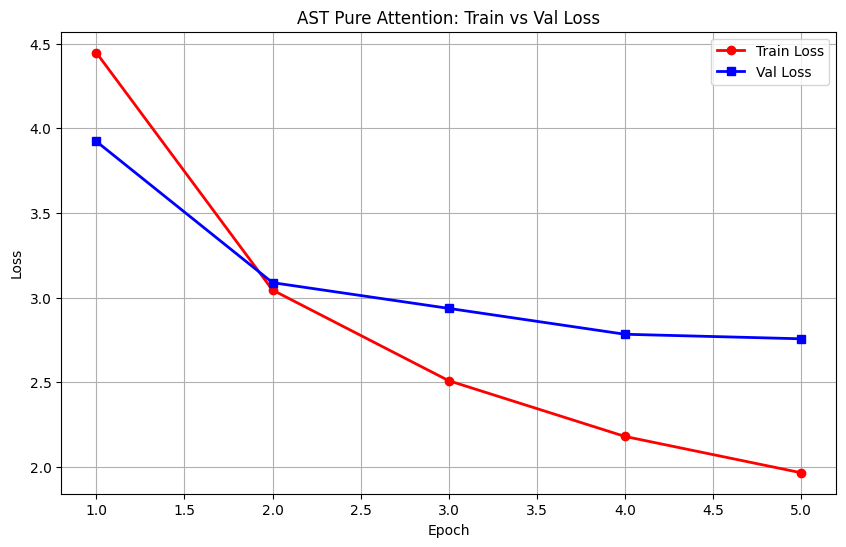

In [34]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), history['train_loss'], marker='o', color='red', linewidth=2, label='Train Loss')
plt.plot(range(1, epochs + 1), history['val_loss'], marker='s', color='blue', linewidth=2, label='Val Loss')
plt.title('AST Pure Attention: Train vs Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

In [39]:
import torch

# 1. Set to eval mode
model.eval()
correct = 0
total = 0
running_val_loss = 0.0

print("Running final validation for AST...")

with torch.no_grad():
    for mels, labs in val_loader:
        mels = mels.to(device)
        labs = labs.to(device)
        
        # AST does NOT take unsqueeze(1)
        with torch.cuda.amp.autocast():
            outputs = model(mels)
            logits = outputs.logits
            loss = criterion(logits, labs)
            
        running_val_loss += loss.item()
        
        # Calculate accuracy
        preds = logits.argmax(dim=1)
        correct += (preds == labs).sum().item()
        total += labs.size(0)

avg_val_loss = running_val_loss / len(val_loader)
val_acc = correct / total

print(f"\n✅ AST Validation Loss: {avg_val_loss:.4f}")
print(f"🏆 AST Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Correct predictions: {correct} / {total}")

# Save the model
torch.save(model.state_dict(), 'ast_pure_attention.pth')
print("✅ Model saved as 'ast_pure_attention.pth'")

Running final validation for AST...


/tmp/ipykernel_48/2177194060.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



✅ AST Validation Loss: 2.6599
🏆 AST Validation Accuracy: 42.55%
Correct predictions: 728 / 1711
✅ Model saved as 'ast_pure_attention.pth'
